# Day 08 — Hospital Readmission Risk Model: analysis

Which features of a hospital stay are **associated with** readmission within 30 days — and how well can a model discriminate readmitted from non-readmitted patients, and how much can its predicted risks be trusted? Two models (logistic regression and HistGradientBoosting) are compared on the same patient-grouped hold-out, on discrimination **and** calibration.

**Data:** Diabetes 130-US Hospitals for Years 1999–2008, UCI Machine Learning Repository (id 296) — 101,766 de-identified inpatient encounters, 130 US hospitals. DOI: https://doi.org/10.24432/C5230J. Licence: CC BY 4.0.

> Clore, J., Cios, K., DeShazo, J., & Strack, B. (2014). Diabetes 130-US Hospitals for Years 1999-2008 [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5230J

**This is an analytical exercise on de-identified example data. It is NOT a clinical tool.** Diabetes patients only, 1999–2008 US practice, no external validation set. Every finding below says “associated with” — never “causes”.

This notebook runs offline from the committed processed CSVs. The training section at the end is guarded: it re-runs training only if the raw CSV is present, otherwise it loads the committed metrics.

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd


def _find_root():
    """Resolve the project root from this notebook's location."""
    here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
    for cand in [here, *here.parents]:
        if (cand / "data" / "processed" / "model_metrics.csv").exists():
            return cand
    raise FileNotFoundError("could not find data/processed/model_metrics.csv")


ROOT = _find_root()
PROCESSED = ROOT / "data" / "processed"
RAW = ROOT / "data" / "raw" / "diabetic_data.csv"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

record = json.loads((PROCESSED / "data_source.json").read_text())
# keep_default_na=False: 'None' is a real category for A1Cresult /
# max_glu_serum ('not measured'), not a missing value.
sample = pd.read_csv(PROCESSED / "sample_encounters.csv", keep_default_na=False)
metrics = pd.read_csv(PROCESSED / "model_metrics.csv")
deciles = pd.read_csv(PROCESSED / "calibration_deciles.csv")
subgroups = pd.read_csv(PROCESSED / "subgroup_metrics.csv")
importance = pd.read_csv(PROCESSED / "feature_importance.csv")

print("source:", record["source"], "| fetched:", record["fetch_date"])
print("raw rows:", record["n_raw"], "| after exclusions:", record["n_after_exclusions"])
print("train rows:", record["split"]["train_rows"], "| test rows:", record["split"]["test_rows"])
print("sample rows:", len(sample), "| sample target rate:", round(sample["target"].mean(), 4))

source: live | fetched: 2026-11-12
raw rows: 101766 | after exclusions: 100114
train rows: 80090 | test rows: 20024
sample rows: 1000 | sample target rate: 0.107


## Q1 — Which features are associated with readmission within 30 days?

First the descriptive half: the 3-class `readmitted` distribution on the full cohort, then <30-day rates by the main features on the committed 1,000-row cleaned sample. The model half (odds ratios) is in Q4.

In [2]:
dist = record["target_distribution_raw"]
total = sum(dist.values())
for k in ("<30", ">30", "NO"):
    print(f"{k:>4}: {dist[k]:>6,} ({dist[k] / total * 100:.2f}%)")


def rate_by(column, groups=None):
    """<30-day rate + n by one feature of the 1,000-row sample."""
    s = sample.copy()
    if groups is not None:
        s[column] = groups(s[column])
    table = s.groupby(column)["target"].agg(["mean", "size"])
    table.columns = ["readmit_rate_<30d", "n"]
    return table.sort_values("readmit_rate_<30d", ascending=False)


print("\n<30-day rate by prior inpatient visits (0 / 1 / 2 / 3+):")
print(rate_by("number_inpatient", lambda c: c.clip(upper=3)))
print("\n<30-day rate by age band:")
print(rate_by("age"))
print("\n<30-day rate by A1C result:")
print(rate_by("A1Cresult"))
print("\n<30-day rate by primary diagnosis group:")
print(rate_by("diag_1_group"))

 <30: 11,357 (11.16%)
 >30: 35,545 (34.93%)
  NO: 54,864 (53.91%)

<30-day rate by prior inpatient visits (0 / 1 / 2 / 3+):
                  readmit_rate_<30d    n
number_inpatient                        
3                          0.226667   75
2                          0.171875   64
1                          0.166667  186
0                          0.071111  675

<30-day rate by age band:
          readmit_rate_<30d    n
age                             
[20-30)            0.235294   17
[10-20)            0.200000    5
[80-90)            0.142857  161
[90-100)           0.117647   34
[70-80)            0.114815  270
[50-60)            0.102410  166
[40-50)            0.089888   89
[60-70)            0.082949  217
[30-40)            0.025000   40
[0-10)             0.000000    1

<30-day rate by A1C result:
           readmit_rate_<30d    n
A1Cresult                        
Norm                0.115385   52
None                0.109489  822
>8                  0.088608   79
>7      

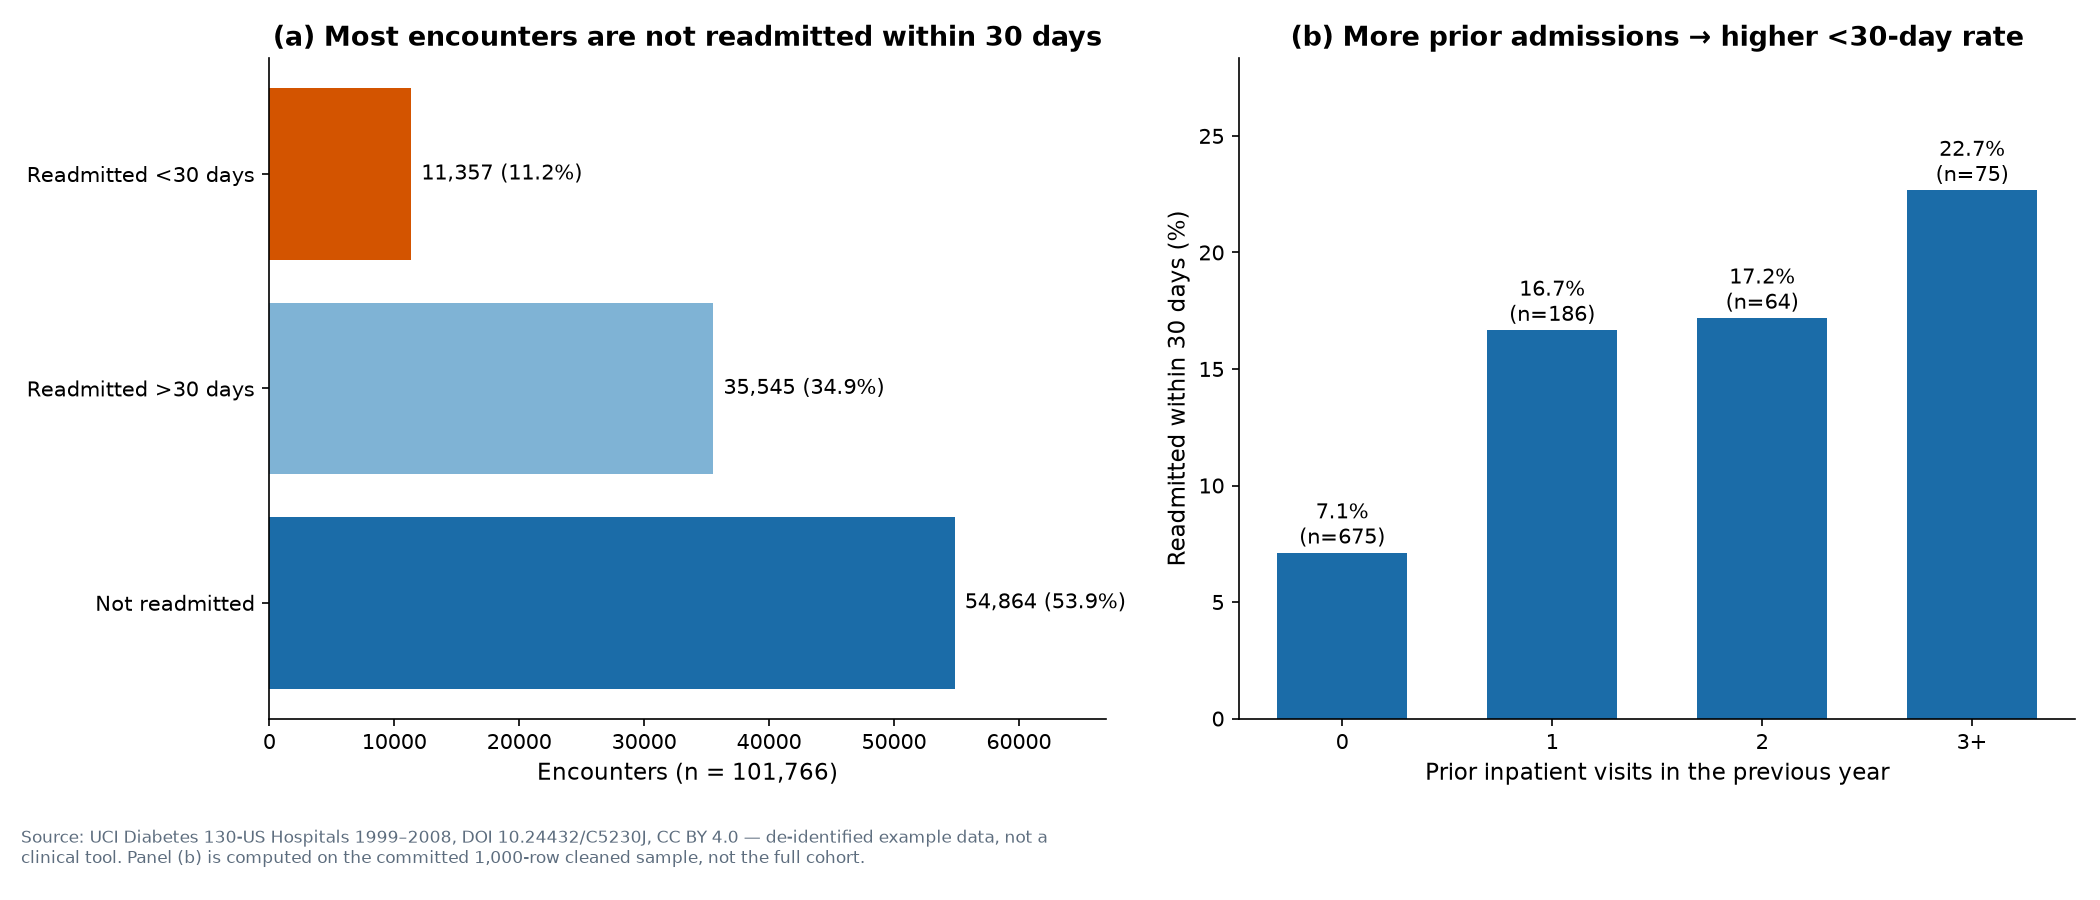

In [3]:
from IPython.display import Image, display

display(Image(str(ROOT / "outputs" / "charts" / "01_readmission_overview.png")))

## Q2 — How well do the models discriminate?

Test-set ROC-AUC and PR-AUC for both models, against the prevalence-only baselines (ROC-AUC 0.5, PR-AUC 0.1116), plus the confusion matrix at threshold 0.5 and 5-fold grouped-CV mean ± std. PR-AUC is the honest metric here: the positive rate is only 11.16%.

,model,roc_auc,pr_auc,brier,brier_baseline,calibration_slope,calibration_intercept,mean_predicted,observed_rate,sensitivity,...,npv,f1,tp,tn,fp,fn,cv_roc_auc_mean,cv_roc_auc_std,cv_pr_auc_mean,cv_pr_auc_std
0,logistic,0.6612,0.2071,0.0971,0.1006,0.9131,-0.1609,0.1125,0.1135,0.0128,...,0.8876,0.0248,29,17712,40,2243,0.6633,0.0032,0.2177,0.0070
1,histgb,0.6761,0.2293,0.0956,0.1006,1.0698,0.1434,0.1126,0.1135,0.0088,...,0.8874,0.0174,20,17742,10,2252,0.6736,0.0033,0.2334,0.0071



Note the threshold-0.5 operating point: sensitivity is very low (logistic 0.013, HistGB 0.009) — at 11% prevalence the models rarely predict 'readmitted' at 0.5. Precision is 0.42 / 0.67 on the few positives they do flag. The threshold was not tuned (plan §4.1).


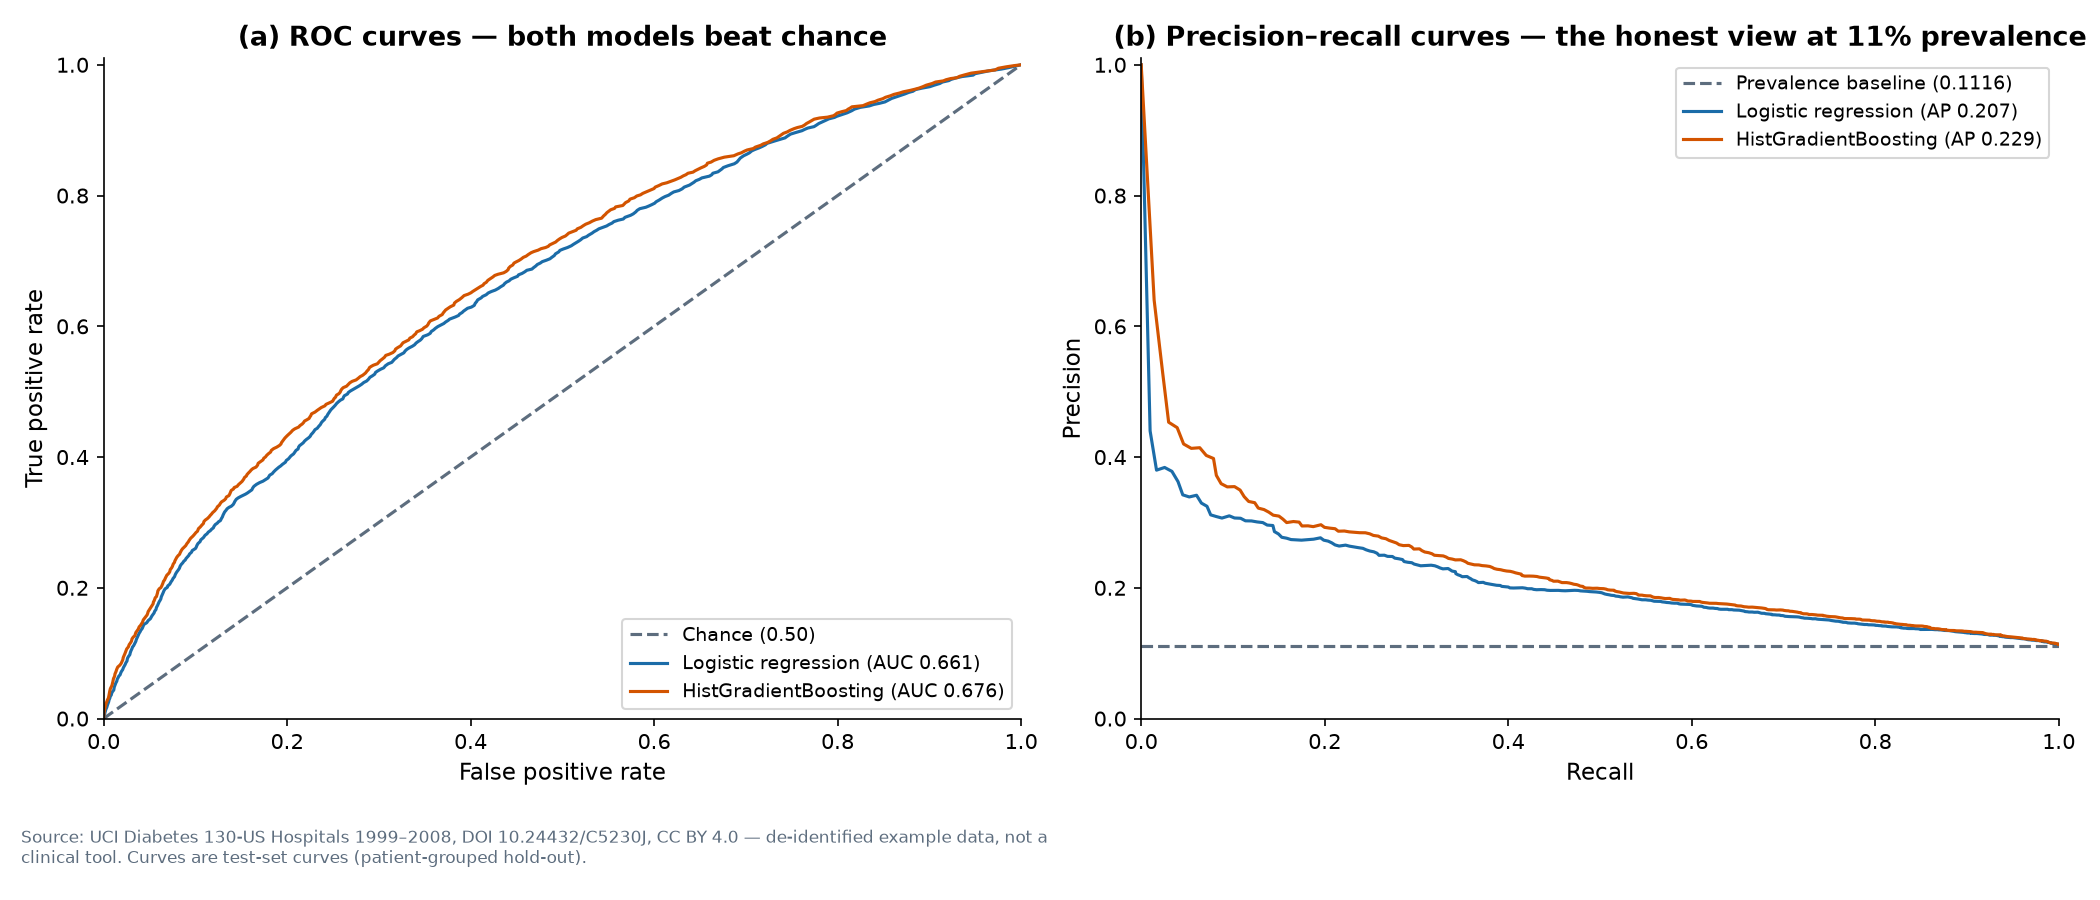

In [4]:
display(metrics)
print("\nNote the threshold-0.5 operating point: sensitivity is very low "
      "(logistic 0.013, HistGB 0.009) — at 11% prevalence the models "
      "rarely predict 'readmitted' at 0.5. Precision is 0.42 / 0.67 on the "
      "few positives they do flag. The threshold was not tuned (plan §4.1).")
display(Image(str(ROOT / "outputs" / "charts" / "02_discrimination.png")))

## Q3 — How well calibrated are the predicted risks?

Brier score against the prevalence-only baseline (≈0.0991 at the raw prevalence 0.1116; 0.1006 at the test-set prevalence 0.1135), calibration slope and intercept (ideal 1 / 0), calibration-in-the-large (mean predicted vs observed rate), and the decile table. No recalibration was applied — calibration is reported as-is; Platt/isotonic scaling is future work.

,model,decile,n,mean_predicted,observed_rate
0,logistic,1,2003,0.046368,0.040439
1,logistic,2,2003,0.062375,0.057414
2,logistic,3,2003,0.071838,0.075886
3,logistic,4,2003,0.080654,0.084373
4,logistic,5,2002,0.089819,0.086414
5,logistic,6,2002,0.100572,0.100899
6,logistic,7,2002,0.113562,0.116384
7,logistic,8,2002,0.130619,0.156843
8,logistic,9,2002,0.159812,0.153846
9,logistic,10,2002,0.269810,0.262238


 logistic: Brier 0.0971 (baseline 0.1006), slope 0.913, intercept -0.161, mean predicted 0.1125 vs observed 0.1135
   histgb: Brier 0.0956 (baseline 0.1006), slope 1.070, intercept +0.143, mean predicted 0.1126 vs observed 0.1135


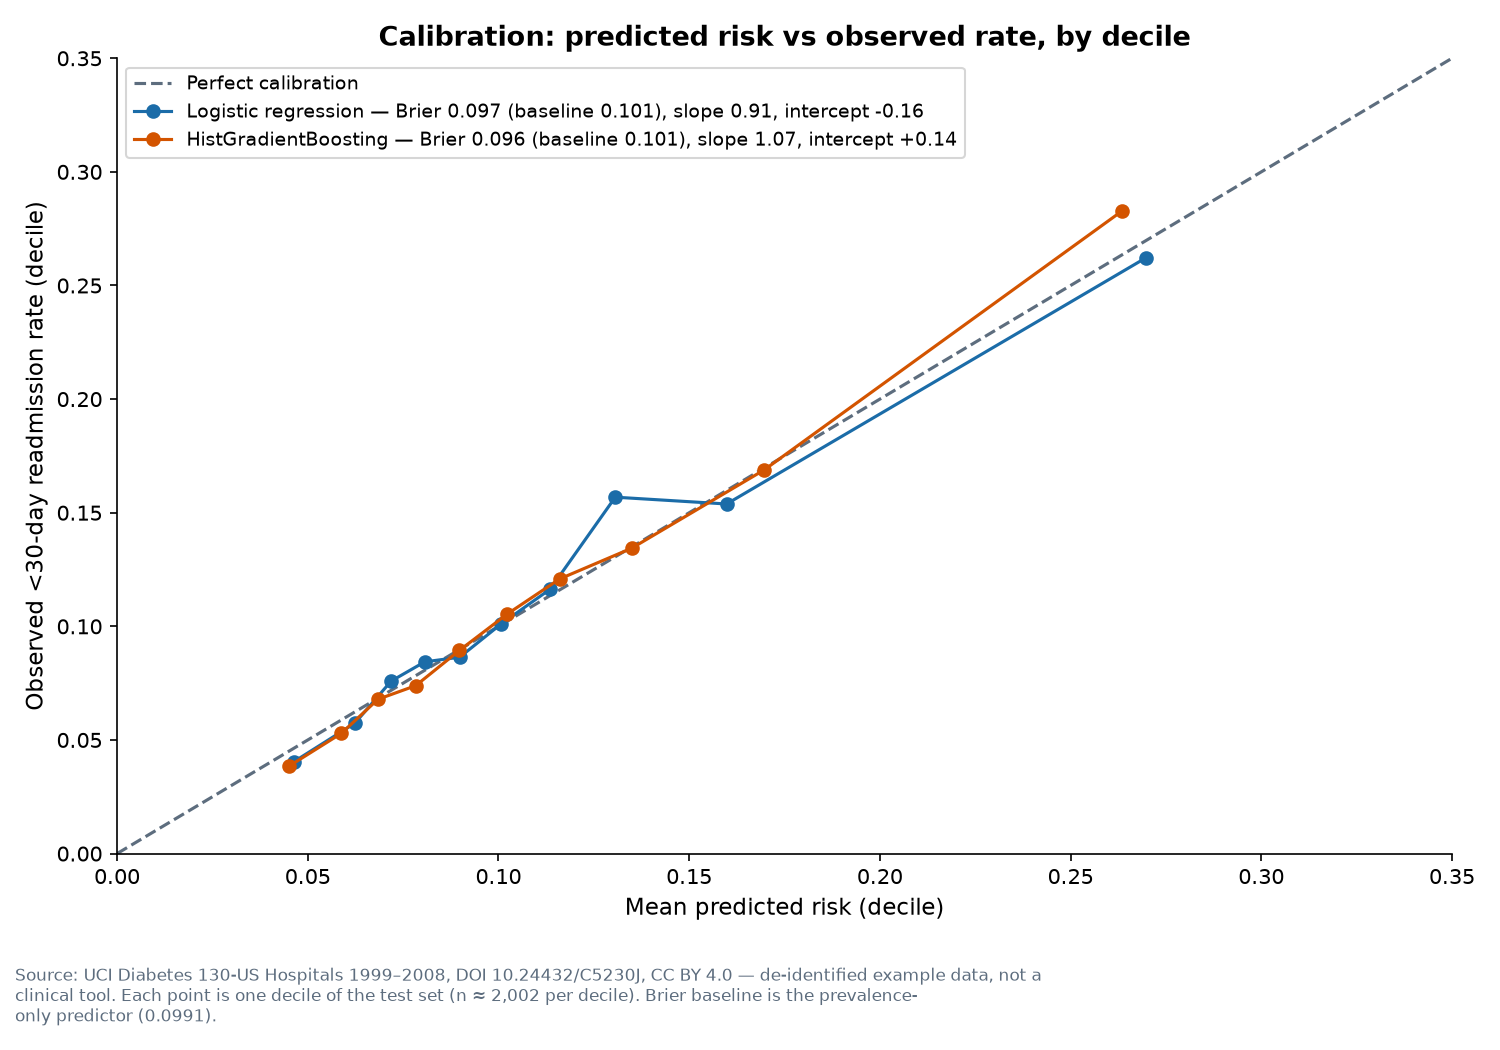

In [5]:
display(deciles)
for _, row in metrics.iterrows():
    print(
        f"{row['model']:>9}: Brier {row['brier']:.4f} (baseline {row['brier_baseline']:.4f}), "
        f"slope {row['calibration_slope']:.3f}, intercept {row['calibration_intercept']:+.3f}, "
        f"mean predicted {row['mean_predicted']:.4f} vs observed {row['observed_rate']:.4f}"
    )
display(Image(str(ROOT / "outputs" / "charts" / "03_calibration.png")))

## Q4 — Is performance consistent across subgroups, and what drives the models?

Test-set ROC-AUC / PR-AUC / Brier by age band, gender and race, with n and positive rate per subgroup (small-n flagged), plus the logistic odds ratios and HistGB permutation importance. The odds ratios are associations from a one-hot model — read them as “this group has higher/lower odds”, not as causes.

ROC-AUC by age band (both models):


model,histgb,logistic
subgroup,,
[0-10),NaN,NaN
[10-20),0.761194,0.747927
[20-30),0.799102,0.753092
[30-40),0.721895,0.722294
[40-50),0.646507,0.651866
[50-60),0.710545,0.704286
[60-70),0.685244,0.666605
[70-80),0.665550,0.646759
[80-90),0.612601,0.606728


ROC-AUC by gender and race (logistic):


,subgroup_type,subgroup,n,positive_rate,roc_auc,pr_auc,small_n
10,gender,Female,10810,0.112673,0.667767,0.213628,False
11,gender,Male,9214,0.114391,0.653668,0.199476,False
12,race,AfricanAmerican,3845,0.112874,0.662668,0.195988,False
13,race,Asian,141,0.127660,0.702349,0.286485,True
14,race,Caucasian,14884,0.114687,0.661484,0.212528,False
15,race,Hispanic,402,0.109453,0.743906,0.276446,True
16,race,Missing,433,0.099307,0.591413,0.136000,True
17,race,Other,319,0.081505,0.595563,0.117258,True


Top 10 logistic odds ratios:


,model,effect_feature,metric,value,extra
0,logistic,cat__discharge_disposition_id_Discharged/trans...,odds_ratio,5.317007,1.670911
1,logistic,cat__discharge_disposition_id_Hospice / home,odds_ratio,0.247124,-1.397867
2,logistic,cat__medical_specialty_Hematology,odds_ratio,3.375796,1.216631
3,logistic,cat__discharge_disposition_id_Discharged/trans...,odds_ratio,3.003806,1.099880
4,logistic,cat__medical_specialty_InfectiousDiseases,odds_ratio,2.676105,0.984362
5,logistic,cat__discharge_disposition_id_Admitted as an i...,odds_ratio,2.542556,0.933170
6,logistic,cat__discharge_disposition_id_Hospice / medica...,odds_ratio,0.413680,-0.882663
7,logistic,cat__medical_specialty_Otolaryngology,odds_ratio,0.434043,-0.834613
8,logistic,cat__discharge_disposition_id_Discharged/trans...,odds_ratio,2.302752,0.834105
9,logistic,cat__medical_specialty_Pediatrics-Endocrinology,odds_ratio,0.442957,-0.814283


Top 10 HistGB permutation importances (test set):


,model,effect_feature,metric,value,extra
20,histgb,number_inpatient,permutation_importance,0.075292,0.006653
21,histgb,discharge_disposition_id,permutation_importance,0.053246,0.000951
22,histgb,diag_1_group,permutation_importance,0.007113,0.000828
23,histgb,payer_code,permutation_importance,0.005921,0.001329
24,histgb,medical_specialty,permutation_importance,0.004877,0.000697
25,histgb,number_emergency,permutation_importance,0.003003,0.000579
26,histgb,time_in_hospital,permutation_importance,0.002840,0.000955
27,histgb,number_diagnoses,permutation_importance,0.002609,0.000454
28,histgb,diabetesMed,permutation_importance,0.002249,0.000441
29,histgb,age,permutation_importance,0.001962,0.000956


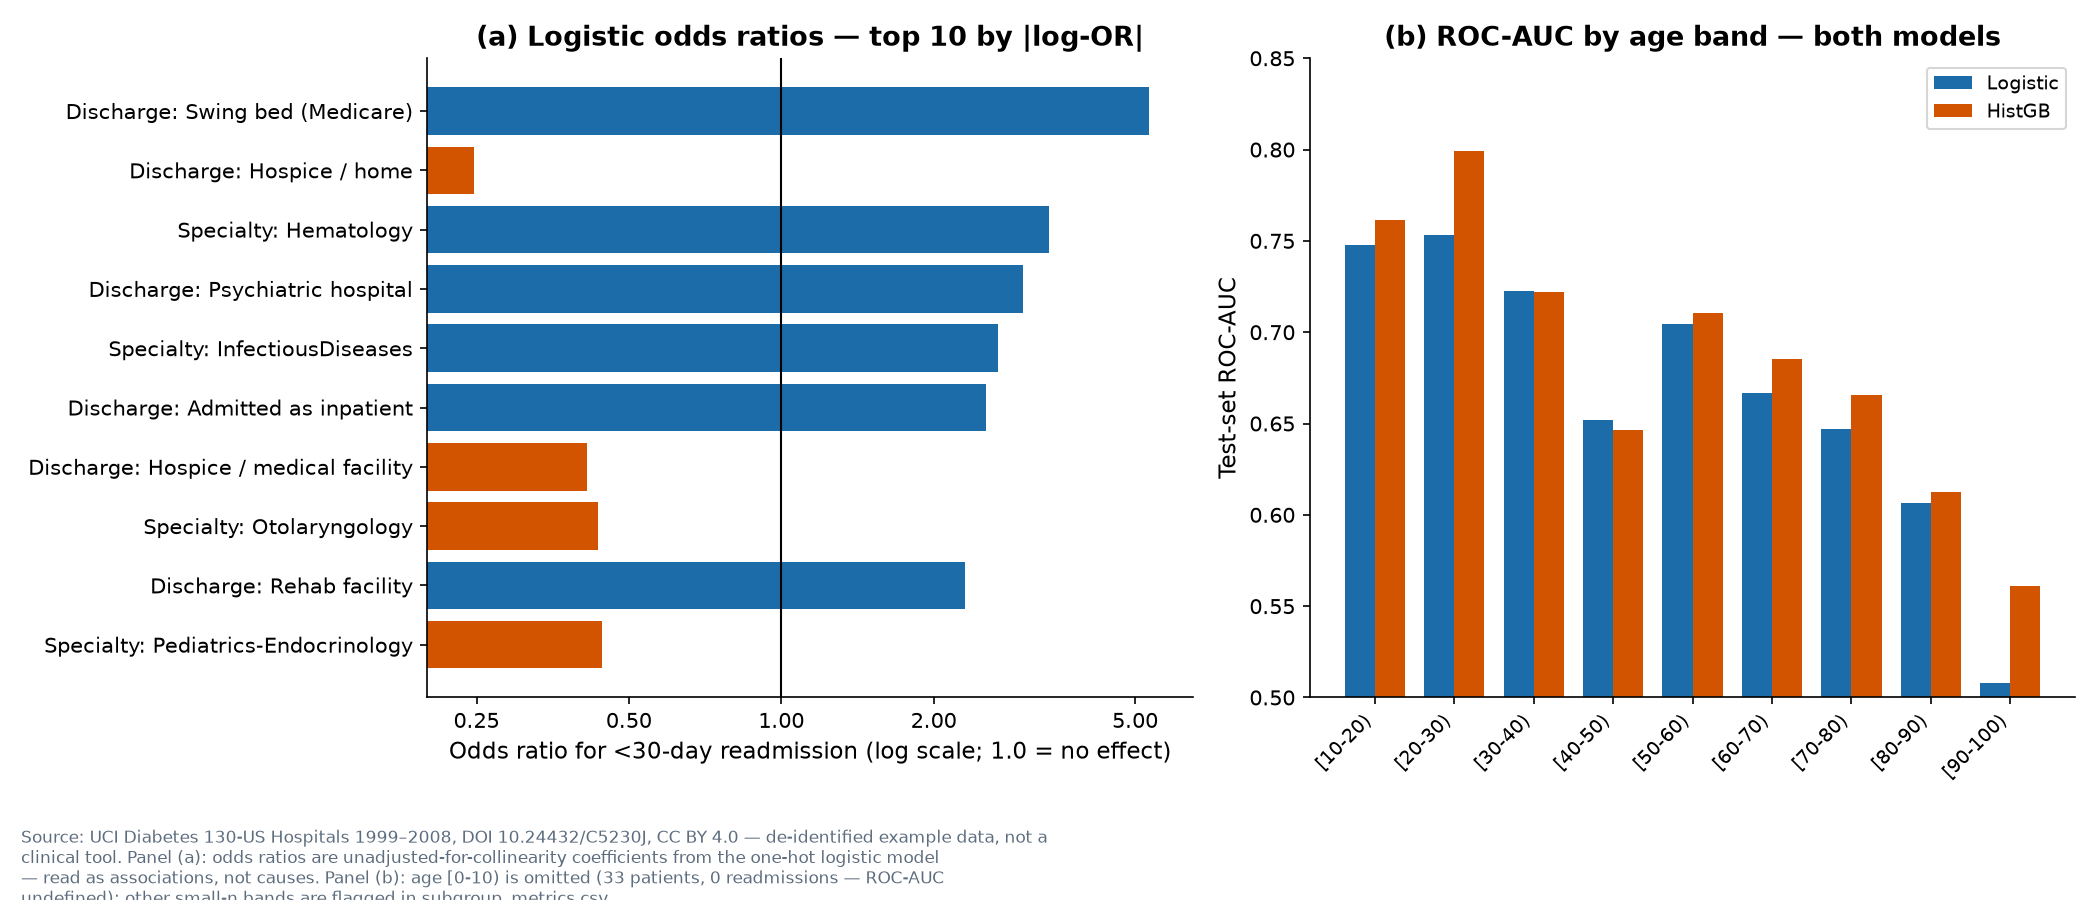

In [6]:
print("ROC-AUC by age band (both models):")
display(
    subgroups[subgroups["subgroup_type"] == "age_band"]
    .pivot(index="subgroup", columns="model", values="roc_auc")
    .reindex(["[0-10)", "[10-20)", "[20-30)", "[30-40)", "[40-50)", "[50-60)",
              "[60-70)", "[70-80)", "[80-90)", "[90-100)"])
)
print("ROC-AUC by gender and race (logistic):")
display(
    subgroups[(subgroups["model"] == "logistic") & (subgroups["subgroup_type"] != "age_band")]
    [["subgroup_type", "subgroup", "n", "positive_rate", "roc_auc", "pr_auc", "small_n"]]
)
print("Top 10 logistic odds ratios:")
odds = importance[(importance["model"] == "logistic") & (importance["metric"] == "odds_ratio")]
display(odds.sort_values("extra", key=abs, ascending=False).head(10))
print("Top 10 HistGB permutation importances (test set):")
perm = importance[(importance["model"] == "histgb") & (importance["metric"] == "permutation_importance")]
display(perm.sort_values("value", ascending=False).head(10))
display(Image(str(ROOT / "outputs" / "charts" / "04_interpretation.png")))

## SQL check — the same question in pandas and in SQL

The <30-day readmission rate by age band (and by prior-inpatient group), computed once in pandas and once in SQL on the committed sample loaded into an in-memory SQLite database. The two must agree — that is the day's SQL element (plan §4.7).

In [7]:
import sqlite3

with sqlite3.connect(":memory:") as conn:
    sample.to_sql("encounters", conn, index=False)
    sql_age = conn.execute(
        "SELECT age, AVG(target) AS rate, COUNT(*) AS n "
        "FROM encounters GROUP BY age ORDER BY age"
    ).fetchall()
    sql_inp = conn.execute(
        "SELECT MIN(number_inpatient, 3) AS grp, AVG(target) AS rate, COUNT(*) AS n "
        "FROM encounters GROUP BY grp ORDER BY grp"
    ).fetchall()

pd_age = sample.groupby("age")["target"].agg(["mean", "size"]).sort_index()
for (age, rate, n), (_, row) in zip(sql_age, pd_age.iterrows()):
    assert age == row.name and abs(rate - row["mean"]) < 1e-9 and n == row["size"]
pd_inp = sample.assign(grp=sample["number_inpatient"].clip(upper=3)).groupby("grp")["target"].agg(["mean", "size"])
for (grp, rate, n), (_, row) in zip(sql_inp, pd_inp.iterrows()):
    assert grp == row.name and abs(rate - row["mean"]) < 1e-9 and n == row["size"]
print("SQL and pandas agree on both groupings.")
print("by age band:", [(a, round(r, 4), n) for a, r, n in sql_age])
print("by prior inpatient visits:", [(g, round(r, 4), n) for g, r, n in sql_inp])

SQL and pandas agree on both groupings.
by age band: [('[0-10)', 0.0, 1), ('[10-20)', 0.2, 5), ('[20-30)', 0.2353, 17), ('[30-40)', 0.025, 40), ('[40-50)', 0.0899, 89), ('[50-60)', 0.1024, 166), ('[60-70)', 0.0829, 217), ('[70-80)', 0.1148, 270), ('[80-90)', 0.1429, 161), ('[90-100)', 0.1176, 34)]
by prior inpatient visits: [(0, 0.0711, 675), (1, 0.1667, 186), (2, 0.1719, 64), (3, 0.2267, 75)]


## Guarded training section

If the raw CSV is present (`data/raw/diabetic_data.csv`), this cell re-runs the full clean → split → train → evaluate path through `src.data_pipeline` and `src.model` and asserts the metrics match the committed `model_metrics.csv` within 0.005. If the raw CSV is absent (the normal checked-out state — the raw file is git-ignored under the data-size exception), training is skipped and the committed metrics are shown instead. Either way the notebook runs with 0 errors, and it never downloads data.

In [8]:
if RAW.exists():
    from src import data_pipeline as pipeline
    from src import model as model_mod

    raw = pipeline.load_raw(RAW)
    mapping = pipeline.load_id_mapping(ROOT / "data" / "raw" / "IDS_mapping.csv")
    clean, _info = pipeline.clean_encounters(raw, mapping)
    train_idx, test_idx = model_mod.patient_group_split(clean)
    train, test = clean.loc[train_idx], clean.loc[test_idx]
    models = model_mod.train_models(train[model_mod.FEATURES], train["target"])
    for name, fitted in models.items():
        result = model_mod.evaluate(fitted, test[model_mod.FEATURES], test["target"])
        committed = metrics.set_index("model").loc[name]
        for key in ("roc_auc", "pr_auc", "brier"):
            assert abs(result[key] - committed[key]) < 0.005, (name, key, result[key], committed[key])
        print(f"{name}: re-trained ROC-AUC {result['roc_auc']:.4f} "
              f"(committed {committed['roc_auc']:.4f}), PR-AUC {result['pr_auc']:.4f} "
              f"(committed {committed['pr_auc']:.4f}) — match within 0.005")
    print("Guarded training section: re-run OK, metrics match the committed CSVs.")
else:
    print("Raw CSV not present (data/raw/diabetic_data.csv is git-ignored); "
          "training skipped — showing the committed test-set metrics instead.")
    display(metrics[["model", "roc_auc", "pr_auc", "brier", "calibration_slope", "calibration_intercept"]])

exclusions: 1652 rows removed (ids [11, 19, 20, 21]: {'11': 1642, '19': 8, '20': 2, '21': 0})


trained logistic


trained histgb


logistic: re-trained ROC-AUC 0.6612 (committed 0.6612), PR-AUC 0.2071 (committed 0.2071) — match within 0.005


histgb: re-trained ROC-AUC 0.6761 (committed 0.6761), PR-AUC 0.2293 (committed 0.2293) — match within 0.005
Guarded training section: re-run OK, metrics match the committed CSVs.


## Limitations — read before quoting any number above

- **Diabetes patients only, 1999–2008 US practice.** Patterns have changed; the model does not transfer to today's hospitals or to non-diabetes patients.
- **No external validation set.** All metrics are from one patient-grouped hold-out of the same 130 hospitals.
- **Encounters after a patient's first readmission are not independent observations** — the data has no encounter ordering to filter on.
- **Rare-category odds ratios are noisy.** The largest odds ratio (discharge to a Medicare swing bed, OR 5.32) comes from a small group; the model card says so. Discharge to hospice (OR 0.25) is protective in the model — those patients are, by definition, not coming back to the same hospital.
- **Discrimination is modest** (ROC-AUC 0.66–0.68, PR-AUC 0.21–0.23): the models rank patients better than chance, but at threshold 0.5 they catch only ~1% of readmissions. Calibration is reasonable (slopes 0.91 / 1.07), so the predicted risks are usable as risks — not as a yes/no rule.
- **Oldest patients are the weak spot:** ROC-AUC falls to 0.51 (logistic) / 0.56 (HistGB) at age [90-100), and [0-10) has too few patients to measure.

See `outputs/model_card.md` for the full model card and `outputs/insights_summary.md` for one finding per research question.